In [2]:
!pip -q install librosa soundfile matplotlib numpy


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


In [3]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np

In [4]:
SR = 16000
N_FFT = 512  # 32 ms przy SR=16000
HOP_LENGTH = 160  # 10 ms przy SR=16000
N_MELS = 64

In [5]:
def wczytaj_audio(sciezka=None):
  if sciezka:
    y, sr = librosa.load(sciezka, sr=SR, mono=True)
    return y.astype(np.float32), sr
  # Jeśli sciezka=None, generuje sygnał testowy chirp (tak jak na zajęciach)
  y = librosa.chirp(fmin=200, fmax=3000, sr=SR, duration=2.0)
  return y.astype(np.float32), SR


def log_mel(y, sr, n_fft=N_FFT, hop_length=HOP_LENGTH, n_mels=N_MELS):
  S = librosa.feature.melspectrogram(
      y=y, sr=sr, n_fft=n_fft, hop_length=hop_length, n_mels=n_mels
  )
  return librosa.power_to_db(S, ref=np.max)


def mfcc(y, sr, n_mfcc=13, n_fft=N_FFT, hop_length=HOP_LENGTH):
  return librosa.feature.mfcc(
      y=y, sr=sr, n_mfcc=n_mfcc, n_fft=n_fft, hop_length=hop_length
  )

=== Samogłoska (Samogłoska.wav) ===
Liczba próbek: 68587
Częstotliwość próbkowania: 16000 Hz
Czas trwania: 4.29 s
Kształt log-mel: (64, 429) (pasma mel x ramki czasowe)
Kształt MFCC:    (13, 429) (współczynniki x ramki czasowe)



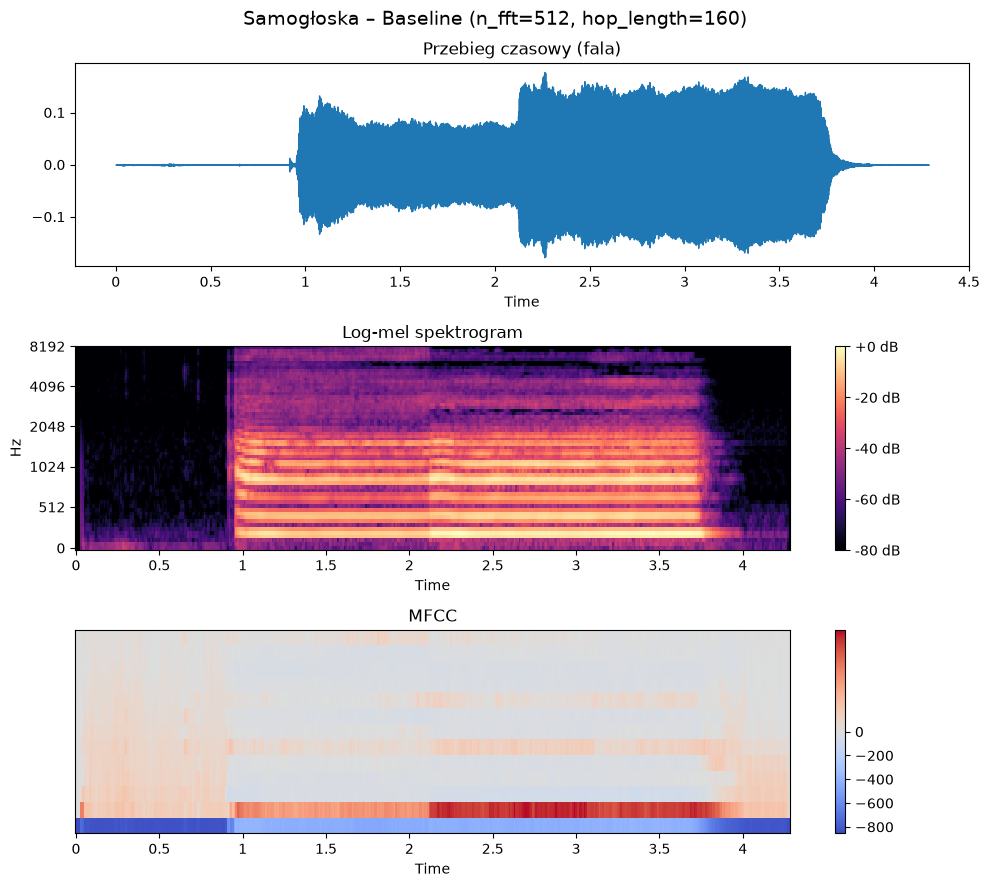

=== Wyraz (Słowo.wav) ===
Liczba próbek: 33088
Częstotliwość próbkowania: 16000 Hz
Czas trwania: 2.07 s
Kształt log-mel: (64, 207) (pasma mel x ramki czasowe)
Kształt MFCC:    (13, 207) (współczynniki x ramki czasowe)



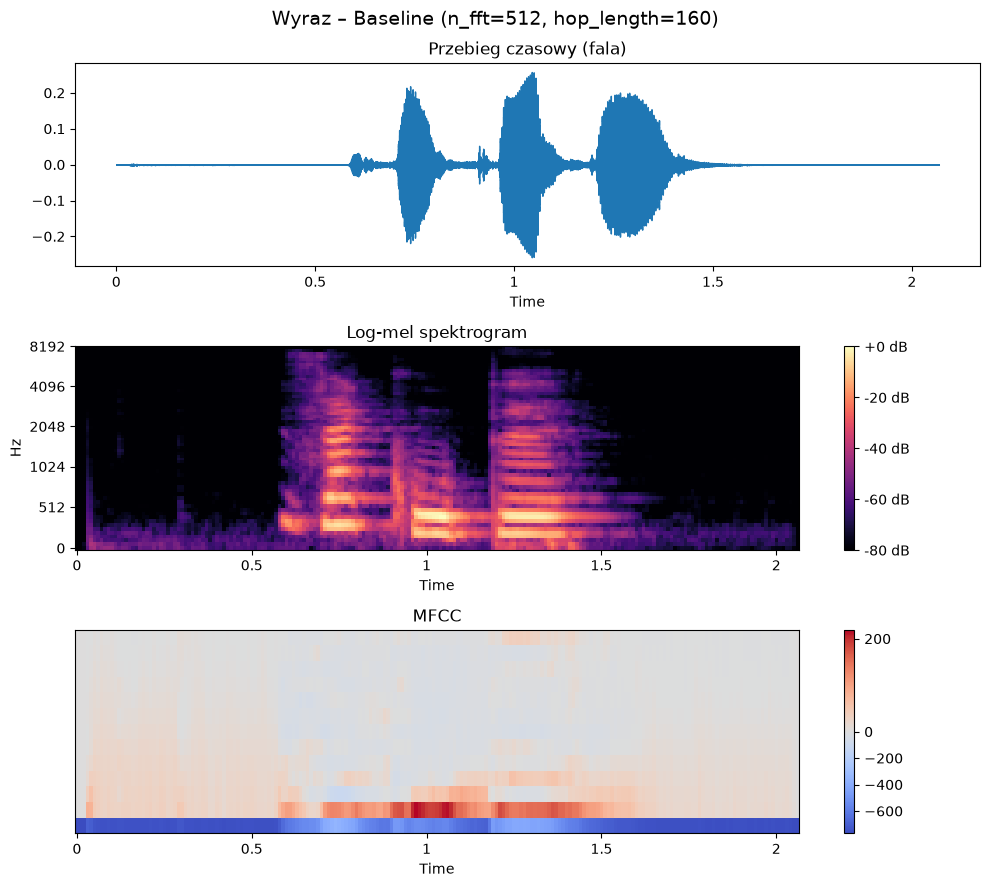

=== Zdanie (Zdanie.wav) ===
Liczba próbek: 60395
Częstotliwość próbkowania: 16000 Hz
Czas trwania: 3.77 s
Kształt log-mel: (64, 378) (pasma mel x ramki czasowe)
Kształt MFCC:    (13, 378) (współczynniki x ramki czasowe)



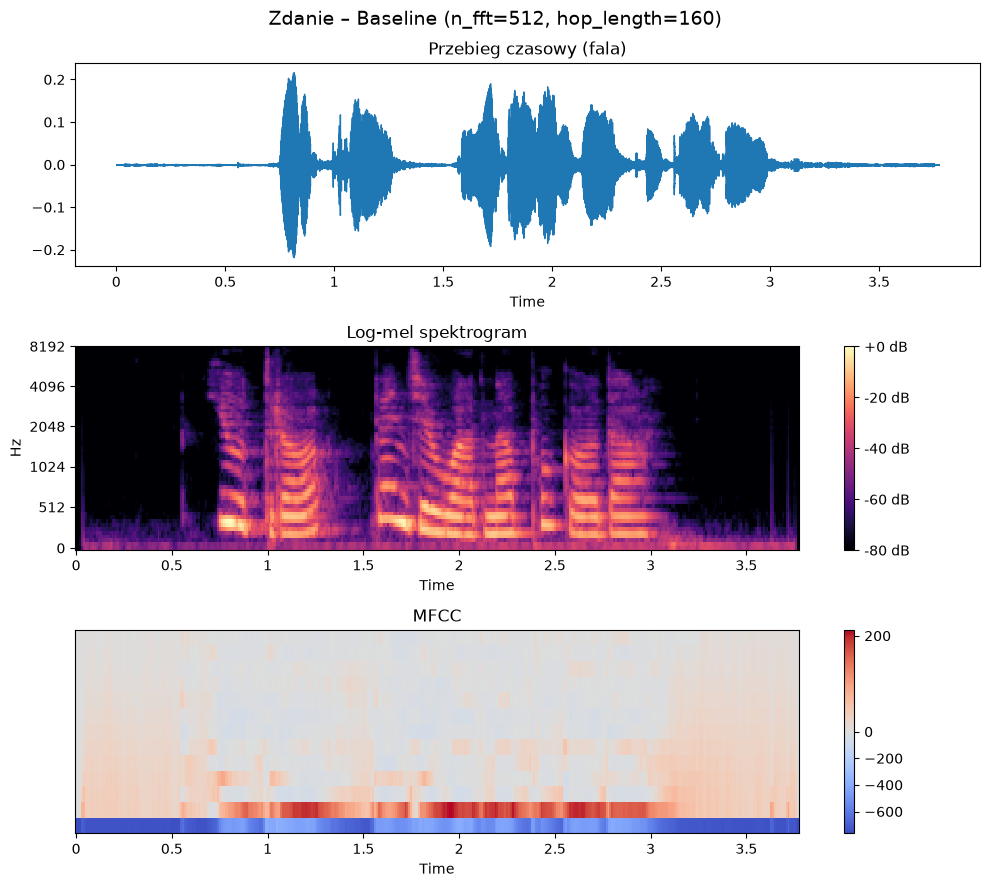

In [ ]:
nagrania = {
    "Samogłoska": "Samogłoska.wav",
    "Wyraz": "Słowo.wav",
    "Zdanie": "Zdanie.wav",
}

for nazwa, plik in nagrania.items():
  y, sr = wczytaj_audio(plik)

  print(f"=== {nazwa} ({plik}) ===")
  print(f"Liczba próbek: {len(y)}")
  print(f"Częstotliwość próbkowania: {sr} Hz")
  print(f"Czas trwania: {len(y) / sr:.2f} s")

  S_db = log_mel(y, sr)
  M = mfcc(y, sr)
  print(f"Kształt log-mel: {S_db.shape} (pasma mel x ramki czasowe)")
  print(f"Kształt MFCC:    {M.shape} (współczynniki x ramki czasowe)\n")

  fig, ax = plt.subplots(3, 1, figsize=(10, 9))
  fig.suptitle(
      f"{nazwa} – Baseline (n_fft={N_FFT}, hop_length={HOP_LENGTH})",
      fontsize=14,
  )

  librosa.display.waveshow(y, sr=sr, ax=ax[0])
  ax[0].set_title("Przebieg czasowy (fala)")

  img1 = librosa.display.specshow(
      S_db, sr=sr, hop_length=HOP_LENGTH, x_axis="time", y_axis="mel", ax=ax[1]
  )
  ax[1].set_title("Log-mel spektrogram")
  fig.colorbar(img1, ax=ax[1], format="%+2.0f dB")

  img2 = librosa.display.specshow(
      M, sr=sr, hop_length=HOP_LENGTH, x_axis="time", ax=ax[2]
  )
  ax[2].set_title("MFCC")
  fig.colorbar(img2, ax=ax[2])

  plt.tight_layout()
  plt.savefig(f"images/baseline_{nazwa.lower()}.png", dpi=300)
  plt.show()



/usr/local/python/3.14.2/lib/python3.14/site-packages/librosa/feature/spectral.py:2170: UserWarning: Empty filters detected in mel frequency basis. Some channels will produce empty responses. Try increasing your sampling rate (and fmax) or reducing n_mels.
  mel_basis = filters.mel(sr=sr, n_fft=n_fft, **kwargs)


[Samogłoska] n_fft=256, hop=80 -> Log-Mel: (64, 858), MFCC: (13, 858)
[Samogłoska] n_fft=512, hop=160 -> Log-Mel: (64, 429), MFCC: (13, 429)
[Samogłoska] n_fft=2048, hop=512 -> Log-Mel: (64, 134), MFCC: (13, 134)


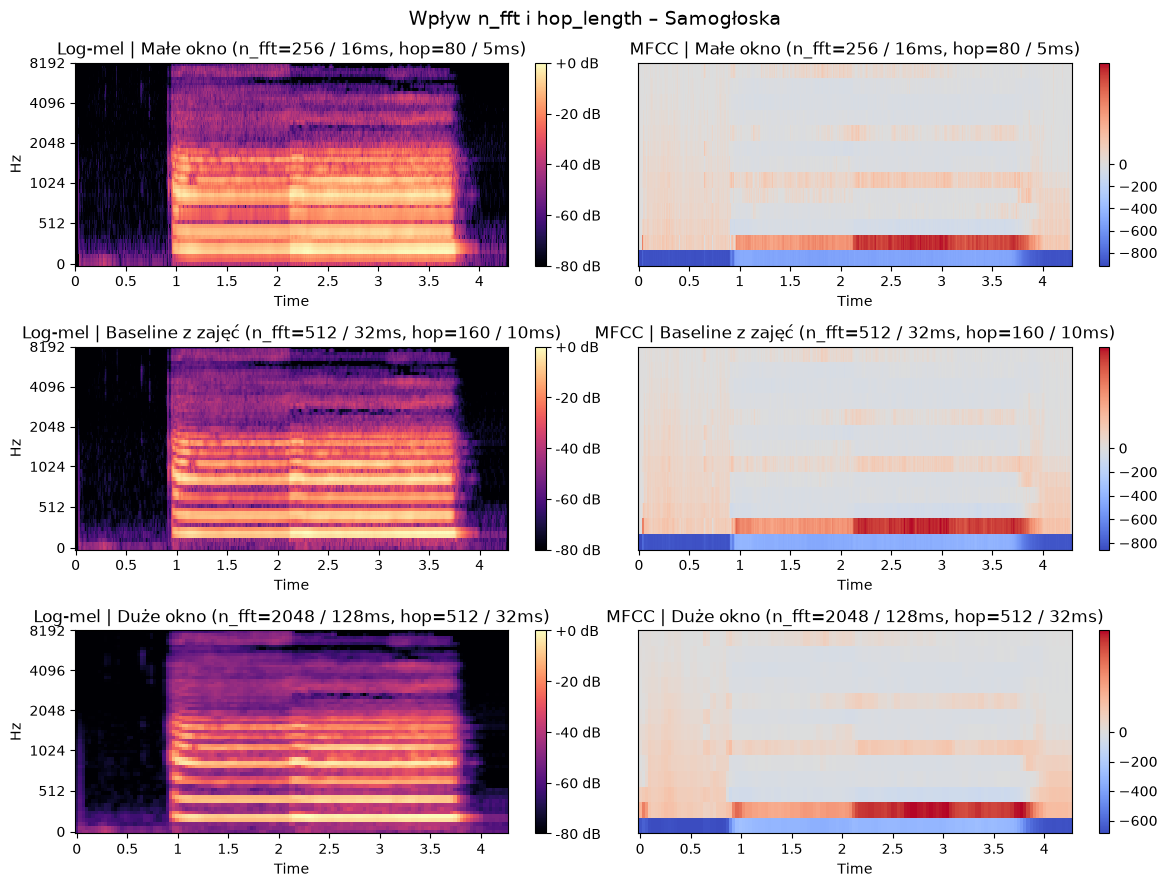

[Wyraz] n_fft=256, hop=80 -> Log-Mel: (64, 414), MFCC: (13, 414)
[Wyraz] n_fft=512, hop=160 -> Log-Mel: (64, 207), MFCC: (13, 207)
[Wyraz] n_fft=2048, hop=512 -> Log-Mel: (64, 65), MFCC: (13, 65)


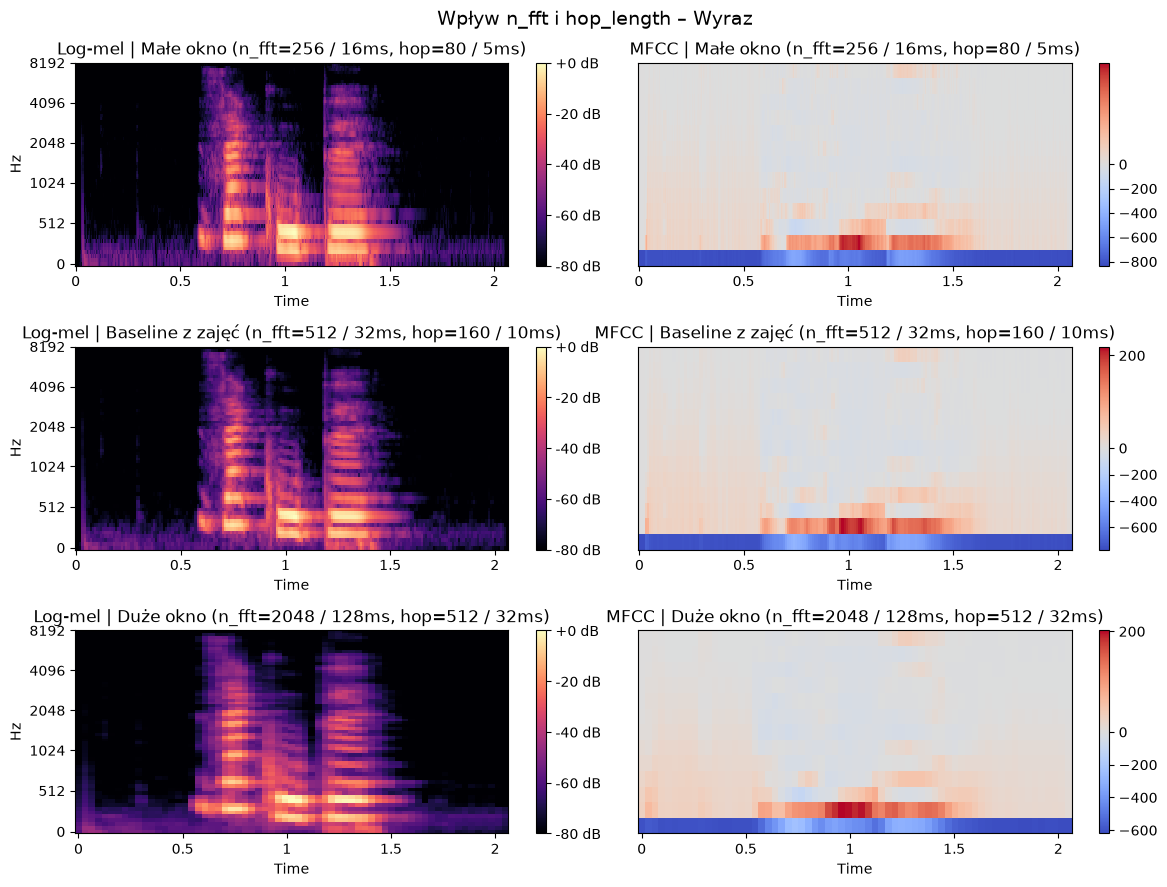

[Zdanie] n_fft=256, hop=80 -> Log-Mel: (64, 755), MFCC: (13, 755)
[Zdanie] n_fft=512, hop=160 -> Log-Mel: (64, 378), MFCC: (13, 378)
[Zdanie] n_fft=2048, hop=512 -> Log-Mel: (64, 118), MFCC: (13, 118)


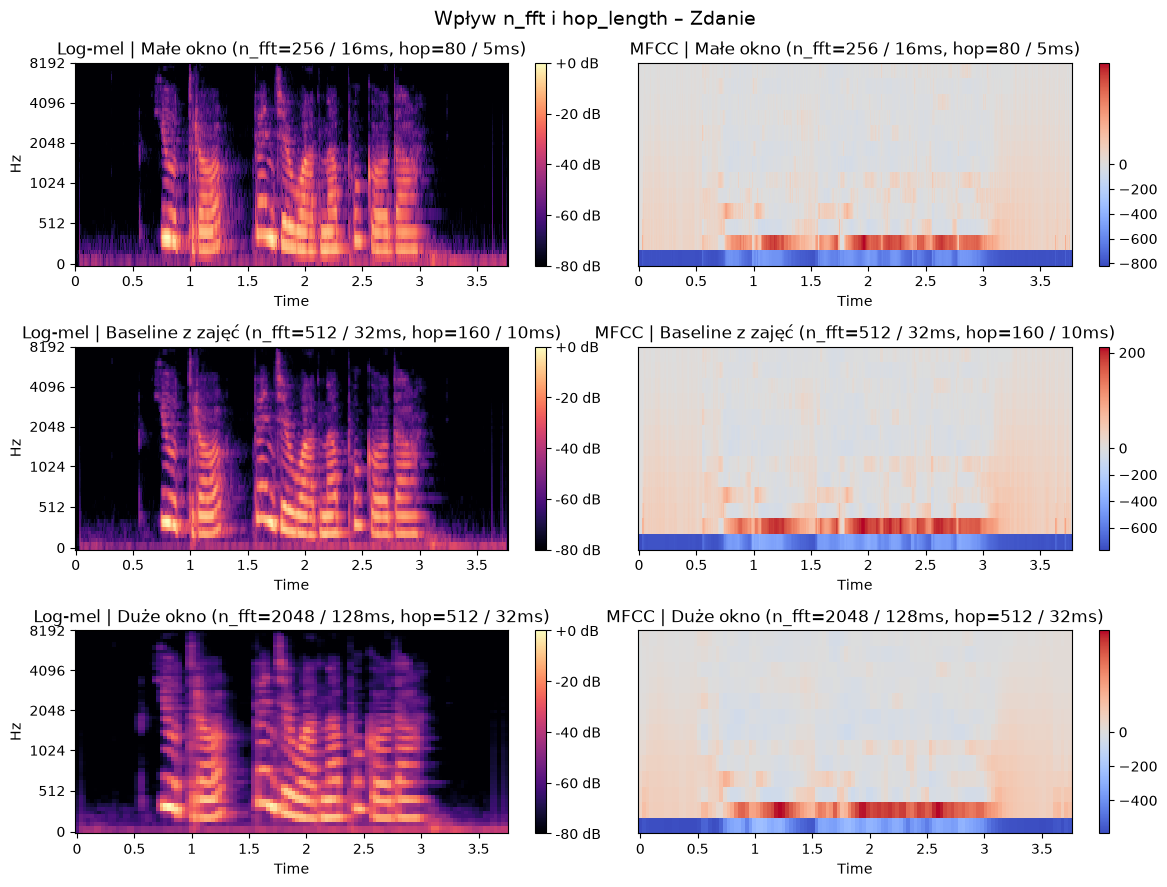

In [ ]:
konfiguracje = [
    (256, 80, "Małe okno (n_fft=256 / 16ms, hop=80 / 5ms)"),
    (512, 160, "Baseline z zajęć (n_fft=512 / 32ms, hop=160 / 10ms)"),
    (2048, 512, "Duże okno (n_fft=2048 / 128ms, hop=512 / 32ms)"),
]

for nazwa, plik in nagrania.items():
  y, sr = wczytaj_audio(plik)

  # Siatka: 3 wiersze (konfiguracje) x 2 kolumny (Log-Mel po lewej, MFCC po prawej)
  fig, ax = plt.subplots(len(konfiguracje), 2, figsize=(12, 9))
  fig.suptitle(f"Wpływ n_fft i hop_length – {nazwa}", fontsize=14)

  for i, (n_fft_val, hop_val, opis) in enumerate(konfiguracje):
    S_db = log_mel(y, sr, n_fft=n_fft_val, hop_length=hop_val)
    M = mfcc(y, sr, n_fft=n_fft_val, hop_length=hop_val)

    print(
        f"[{nazwa}] n_fft={n_fft_val}, hop={hop_val} -> Log-Mel: {S_db.shape},"
        f" MFCC: {M.shape}"
    )

    img1 = librosa.display.specshow(
        S_db, sr=sr, hop_length=hop_val, x_axis="time", y_axis="mel", ax=ax[i, 0]
    )
    ax[i, 0].set_title(f"Log-mel | {opis}")
    fig.colorbar(img1, ax=ax[i, 0], format="%+2.0f dB")

    img2 = librosa.display.specshow(
        M, sr=sr, hop_length=hop_val, x_axis="time", ax=ax[i, 1]
    )
    ax[i, 1].set_title(f"MFCC | {opis}")
    fig.colorbar(img2, ax=ax[i, 1])

  plt.tight_layout()
  plt.savefig(f"images/porownanie_parametrow_{nazwa.lower()}.png", dpi=300)
  plt.show()
